# Лабораторная работа 9. Предсказание жанра фильма по описанию

Короткий профиль запускает обе модели на общем разбиении и сохраняет матрицы ошибок.
Для полного опыта смените профиль на full. Полный скрипт находится в соседней папке Python_Code.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
candidates = [entry for path in (here, *here.parents)
              for entry in (path, path / 'Deep_Learning_Textbook')]
book = next(entry for entry in candidates if (entry / 'Python_Code/Chapter_09').is_dir())
sys.path.insert(0, str(book / 'Python_Code/Chapter_09'))
from movie_genre import main

archive = book.parent / 'Лекция 6/Семинар 6/sf-dl-movie-genre-classification.zip'
assert archive.is_file(), f'Укажите путь к локальному архиву: {archive}'
arguments = ['--archive', str(archive), '--profile', 'short', '--seed', '42']

## Обучение и тест

Следите за валидационной метрикой во время выбора эпохи. Сумма элементов каждой матрицы должна совпадать с размером теста.

In [2]:
reports = main(arguments)

masked_attention=[0.7310585786300049, 0.26894142136999516, 0.0] context=[1.4621171572600098, 1.0757656854799806]


duplicates_removed=75 vocabulary=4002
profile=short train=320 val=80 test=80
classes=comedy,documentary,drama,horror


epoch=1 val_macro_f1=0.249193
GRU_parameters=206404 best_epoch=1
NaiveBayes val_f1=0.597316 test_accuracy=0.662500 test_macro_f1=0.658766
8 0 12 0
0 19 1 0
1 3 16 0
1 2 7 10
GRU val_f1=0.249193 test_accuracy=0.262500 test_macro_f1=0.236218
7 2 9 2
6 10 3 1
4 11 3 2
5 9 5 1


## Независимая сверка

Строки соответствуют истинным классам, столбцы — прогнозам. Для каждого класса F1 равна удвоенному диагональному элементу, делённому на сумму строки и столбца. Усредняем по классам с одинаковым весом.

In [3]:
for name, report in reports.items():
    m = report['matrix']
    n = len(m)
    accuracy = sum(m[i][i] for i in range(n)) / sum(map(sum, m))
    f1 = sum(2*m[i][i] / max(1, sum(m[i]) + sum(row[i] for row in m))
             for i in range(n)) / n
    assert abs(accuracy - report['accuracy']) < 1e-6
    assert abs(f1 - report['macro_f1']) < 1e-6
    print(f'Сверено {name}: accuracy={accuracy:.4f}, macro-F1={f1:.4f}')

Сверено NaiveBayes: accuracy=0.6625, macro-F1=0.6588
Сверено GRU: accuracy=0.2625, macro-F1=0.2362


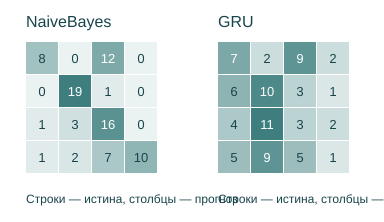

In [4]:
from html import escape
from IPython.display import SVG, display

n = len(next(iter(reports.values()))['matrix'])
size = 33
step = n * size + 60
width = 2 * step
height = n * size + 90
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
         f'viewBox="0 0 {width} {height}" role="img" aria-label="Две матрицы ошибок">',
         '<rect width="100%" height="100%" fill="white"/>']
for k, (name, report) in enumerate(reports.items()):
    base = k * step + 26
    matrix = report['matrix']
    scale = max(max(row) for row in matrix)
    parts.append(f'<text x="{base}" y="27" font-family="Arial" font-size="16" fill="#17444B">{escape(name)}</text>')
    for i, row in enumerate(matrix):
        for j, val in enumerate(row):
            x, y = base + size*j, 42 + size*i
            opacity = 0.10 + 0.85 * val / scale
            parts.append(f'<rect x="{x}" y="{y}" width="{size-1}" height="{size-1}" fill="#357878" opacity="{opacity:.3f}"/>')
            color = 'white' if opacity > .6 else '#17444B'
            parts.append(f'<text x="{x+16}" y="{y+21}" text-anchor="middle" font-family="Arial" font-size="13" fill="{color}">{val}</text>')
    parts.append(f'<text x="{base}" y="{height-19}" font-family="Arial" font-size="12" fill="#17444B">Строки — истина, столбцы — прогноз</text>')
parts.append('</svg>')
display(SVG(''.join(parts)))

## Задание

Объясните две крупнейшие внедиагональные ячейки. Сравните короткий и полный профили по числу примеров и эпох. Укажите, какие выводы можно делать только на общем тесте.